# Exploratory Data Analysis of Books Dataset

## Introduction

Exploratory Data Analysis (EDA) is the process of examining and analyzing a dataset to understand its structure, patterns, distributions, relationships, and possible data quality issues.

This project analyzes a books dataset containing information about books, authors, ratings, genres, publication dates, publishers, number of ratings, popularity scores, and other book-related attributes.

The objective of this analysis is to identify patterns in book ratings, popularity, publication trends, authors, genres, and other factors that may help us understand the characteristics of popular and highly rated books.

### 1. Import Required Libraries

Import the Python libraries needed for data analysis and visualization. `pandas` and `numpy` help work with data, `matplotlib` and `seaborn` create graphs, and `warnings` controls warning messages.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

## Import Dataset

### 2. Load the Dataset

Read the `bookdataset.csv` file and store its contents in a DataFrame named `df`. A DataFrame is a table containing rows and columns.

In [2]:
df = pd.read_csv("bookdataset.csv")

## Display the First 5 Rows of the Dataset

### 3. View the First Five Rows

Use `df.head()` to display the first five rows. This gives us a quick look at the dataset and its column names.

In [3]:
df.head()

,bookId,title,series,author,rating,description,language,isbn,genres,characters,...,firstPublishDate,awards,numRatings,ratingsByStars,likedPercent,setting,coverImg,bbeScore,bbeVotes,price
0,2767052-the-hunger-games,The Hunger Games,The Hunger Games #1,Suzanne Collins,4.33,WINNING MEANS FAME AND FORTUNE.LOSING MEANS CE...,English,9780439023481,"['Young Adult', 'Fiction', 'Dystopia', 'Fantas...","['Katniss Everdeen', 'Peeta Mellark', 'Cato (H...",...,NaN,['Locus Award Nominee for Best Young Adult Boo...,6376780,"['3444695', '1921313', '745221', '171994', '93...",96.0,"['District 12, Panem', 'Capitol, Panem', 'Pane...",https://i.gr-assets.com/images/S/compressed.ph...,2993816,30516,5.09
1,2.Harry_Potter_and_the_Order_of_the_Phoenix,Harry Potter and the Order of the Phoenix,Harry Potter #5,"J.K. Rowling, Mary GrandPré (Illustrator)",4.50,There is a door at the end of a silent corrido...,English,9780439358071,"['Fantasy', 'Young Adult', 'Fiction', 'Magic',...","['Sirius Black', 'Draco Malfoy', 'Ron Weasley'...",...,06/21/03,['Bram Stoker Award for Works for Young Reader...,2507623,"['1593642', '637516', '222366', '39573', '14526']",98.0,['Hogwarts School of Witchcraft and Wizardry (...,https://i.gr-assets.com/images/S/compressed.ph...,2632233,26923,7.38
2,2657.To_Kill_a_Mockingbird,To Kill a Mockingbird,To Kill a Mockingbird,Harper Lee,4.28,The unforgettable novel of a childhood in a sl...,English,9999999999999,"['Classics', 'Fiction', 'Historical Fiction', ...","['Scout Finch', 'Atticus Finch', 'Jem Finch', ...",...,07/11/60,"['Pulitzer Prize for Fiction (1961)', 'Audie A...",4501075,"['2363896', '1333153', '573280', '149952', '80...",95.0,"['Maycomb, Alabama (United States)']",https://i.gr-assets.com/images/S/compressed.ph...,2269402,23328,NaN
3,1885.Pride_and_Prejudice,Pride and Prejudice,NaN,"Jane Austen, Anna Quindlen (Introduction)",4.26,Alternate cover edition of ISBN 9780679783268S...,English,9999999999999,"['Classics', 'Fiction', 'Romance', 'Historical...","['Mr. Bennet', 'Mrs. Bennet', 'Jane Bennet', '...",...,01/28/13,[],2998241,"['1617567', '816659', '373311', '113934', '767...",94.0,"['United Kingdom', 'Derbyshire, England (Unite...",https://i.gr-assets.com/images/S/compressed.ph...,1983116,20452,NaN
4,41865.Twilight,Twilight,The Twilight Saga #1,Stephenie Meyer,3.60,About three things I was absolutely positive.\...,English,9780316015844,"['Young Adult', 'Fantasy', 'Romance', 'Vampire...","['Edward Cullen', 'Jacob Black', 'Laurent', 'R...",...,10/05/05,"['Georgia Peach Book Award (2007)', 'Buxtehude...",4964519,"['1751460', '1113682', '1008686', '542017', '5...",78.0,"['Forks, Washington (United States)', 'Phoenix...",https://i.gr-assets.com/images/S/compressed.ph...,1459448,14874,2.1


## Display the Last 5 Rows of the Dataset

### 4. View the Last Five Rows

Use `df.tail()` to display the last five rows of the dataset.

In [5]:
df.tail()

,bookId,title,series,author,rating,description,language,isbn,genres,characters,...,firstPublishDate,awards,numRatings,ratingsByStars,likedPercent,setting,coverImg,bbeScore,bbeVotes,price
52473,11492014-fractured,Fractured,Fateful #2,Cheri Schmidt (Goodreads Author),4.00,The Fateful Trilogy continues with Fractured. ...,English,2940012616562,"['Vampires', 'Paranormal', 'Young Adult', 'Rom...",[],...,NaN,[],871,"['311', '310', '197', '42', '11']",94.0,[],https://i.gr-assets.com/images/S/compressed.ph...,0,1,NaN
52474,11836711-anasazi,Anasazi,Sense of Truth #2,Emma Michaels,4.19,"'Anasazi', sequel to 'The Thirteenth Chime' by...",English,9999999999999,"['Mystery', 'Young Adult']",[],...,August 3rd 2011,[],37,"['16', '14', '5', '2', '0']",95.0,[],https://i.gr-assets.com/images/S/compressed.ph...,0,1,NaN
52475,10815662-marked,Marked,Soul Guardians #1,Kim Richardson (Goodreads Author),3.70,--READERS FAVORITE AWARDS WINNER 2011--Sixteen...,English,9781461017097,"['Fantasy', 'Young Adult', 'Paranormal', 'Ange...",[],...,March 15th 2011,"[""Readers' Favorite Book Award (2011)""]",6674,"['2109', '1868', '1660', '647', '390']",84.0,[],https://i.gr-assets.com/images/S/compressed.ph...,0,1,7.37
52476,11330278-wayward-son,Wayward Son,NaN,"Tom Pollack (Goodreads Author), John Loftus (G...",3.85,A POWERFUL TREMOR UNEARTHS AN ANCIENT SECRETBu...,English,9781450755634,"['Fiction', 'Mystery', 'Historical Fiction', '...",[],...,April 5th 2011,[],238,"['77', '78', '59', '19', '5']",90.0,[],https://i.gr-assets.com/images/S/compressed.ph...,0,1,2.86
52477,10991547-daughter-of-helaman,Daughter of Helaman,Stripling Warrior #1,Misty Moncur (Goodreads Author),4.02,Fighting in Helaman's army is Keturah's deepes...,English,9781599554976,"['Lds Fiction', 'Historical Fiction', 'Young A...",[],...,NaN,[],246,"['106', '73', '42', '17', '8']",90.0,[],https://i.gr-assets.com/images/S/compressed.ph...,0,1,5.20


## Dataset Shape

### 5. Check the Dataset Shape

Display the number of rows and columns. `df.shape[0]` gives the row count, while `df.shape[1]` gives the column count.

In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 52478
Number of columns: 25


## Data Cleaning

### 6. Check Missing Values

Use `isna().sum()` to count missing values in each column. This helps identify incomplete data that may need cleaning.

In [8]:
df.isna().sum()

bookId                  0
title                   0
series              29008
author                  0
rating                  0
description          1338
language             3806
isbn                    0
genres                  0
characters              0
bookFormat           1473
edition             47523
pages                2347
publisher            3696
publishDate           880
firstPublishDate    21326
awards                  0
numRatings              0
ratingsByStars          0
likedPercent          622
setting                 0
coverImg              605
bbeScore                0
bbeVotes                0
price               14365
dtype: int64

## Check Duplicate Records

### 7. Check Duplicate Rows

Use `duplicated().sum()` to count rows that are exact duplicates of earlier rows.

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 50


### 8. Remove Duplicate Rows

Use `drop_duplicates()` to remove duplicate rows. `inplace=True` applies the change directly to `df`.

In [10]:
df.drop_duplicates(inplace=True)

## Check Data Types

### 9. Check Data Types

Display the data type of each column, such as integer, decimal, or text. This helps check whether each column is stored in a suitable format.

In [11]:
print(df.dtypes)

bookId               object
title                object
series               object
author               object
rating              float64
description          object
language             object
isbn                 object
genres               object
characters           object
bookFormat           object
edition              object
pages                object
publisher            object
publishDate          object
firstPublishDate     object
awards               object
numRatings            int64
ratingsByStars       object
likedPercent        float64
setting              object
coverImg             object
bbeScore              int64
bbeVotes              int64
price                object
dtype: object


## Data Understanding

### 10. Get Dataset Information

Use `df.info()` to view the column names, non-null value counts, data types, and memory usage.

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 52428 entries, 0 to 52477
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   bookId            52428 non-null  object 
 1   title             52428 non-null  object 
 2   series            23445 non-null  object 
 3   author            52428 non-null  object 
 4   rating            52428 non-null  float64
 5   description       51092 non-null  object 
 6   language          48627 non-null  object 
 7   isbn              52428 non-null  object 
 8   genres            52428 non-null  object 
 9   characters        52428 non-null  object 
 10  bookFormat        50955 non-null  object 
 11  edition           4949 non-null   object 
 12  pages             50085 non-null  object 
 13  publisher         48736 non-null  object 
 14  publishDate       51549 non-null  object 
 15  firstPublishDate  31125 non-null  object 
 16  awards            52428 non-null  object

### 11. Summary Statistics

Use `describe()` to calculate summary statistics for numerical columns, such as count, mean, standard deviation, minimum, quartiles, and maximum.

In [13]:
print(df.describe())

             rating    numRatings  likedPercent      bbeScore      bbeVotes
count  52428.000000  5.242800e+04  51807.000000  5.242800e+04  52428.000000
mean       4.021865  1.789260e+04     92.231938  1.985832e+03     22.549535
std        0.367116  1.039932e+05      5.988683  3.516985e+04    369.333934
min        0.000000  0.000000e+00      0.000000  0.000000e+00     -4.000000
25%        3.820000  3.410000e+02     90.000000  8.400000e+01      1.000000
50%        4.030000  2.309500e+03     94.000000  9.700000e+01      1.000000
75%        4.230000  9.389000e+03     96.000000  1.870000e+02      2.000000
max        5.000000  7.048471e+06    100.000000  2.993816e+06  30516.000000


### 12. Most Frequent Authors

Count how many times each author appears and display the ten most frequent authors.

In [14]:
print(df['author'].value_counts().head(10))

Nora Roberts (Goodreads Author)       86
Agatha Christie                       72
Stephen King (Goodreads Author)       66
Erin Hunter                           59
Bella Forrest (Goodreads Author)      53
Meg Cabot (Goodreads Author)          52
Lucian Bane (Goodreads Author)        49
Terry Pratchett                       48
Karen Kingsbury (Goodreads Author)    48
Bonnie Bryant                         47
Name: author, dtype: int64


### 13. Most Frequent Languages

Count the books in each language and display the ten most common languages.

In [15]:
print(df['language'].value_counts().head(10))

English       42635
Arabic         1036
Spanish         684
French          576
German          525
Indonesian      370
Portuguese      363
Italian         254
Dutch           214
Turkish         211
Name: language, dtype: int64


### 14. Most Common Book Formats

Count how often each book format appears and display the ten most common formats.

In [16]:
print(df['bookFormat'].value_counts().head(10))

Paperback                26748
Hardcover                12257
Kindle Edition            5824
Mass Market Paperback     2566
ebook                     2545
Audio CD                   145
Nook                       138
Audiobook                  106
Unknown Binding             99
Trade Paperback             53
Name: bookFormat, dtype: int64


## Univariate Analysis Distribution of Book Ratings

### 15. Distribution of Book Ratings

Create a histogram of book ratings. The bars show how many books fall within each rating range, and the KDE curve gives a smoothed view of the distribution.

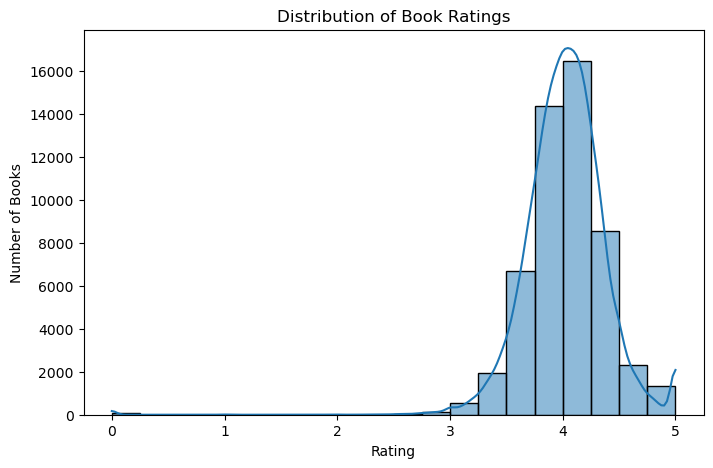

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(df['rating'], bins=20, kde=True)

plt.title('Distribution of Book Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Books')

plt.show()

### 16. Rating Summary Statistics

Display summary statistics for the `rating` column to understand its count, average, spread, and range.

In [18]:
print(df['rating'].describe())

count    52428.000000
mean         4.021865
std          0.367116
min          0.000000
25%          3.820000
50%          4.030000
75%          4.230000
max          5.000000
Name: rating, dtype: float64


### 17. Top 10 Books by Number of Ratings

Sort books by `numRatings` from highest to lowest and display the ten books with the most ratings, along with their authors and ratings.

In [19]:
top_books = df.sort_values(
    by='numRatings',
    ascending=False
).head(10)

print(top_books[['title', 'author', 'rating', 'numRatings']])

                                     title  \
32   Harry Potter and the Sorcerer's Stone   
0                         The Hunger Games   
4                                 Twilight   
2                    To Kill a Mockingbird   
27                        The Great Gatsby   
10                  The Fault in Our Stars   
80                                    1984   
3                      Pride and Prejudice   
21                               Divergent   
147    The Hobbit, or There and Back Again   

                                            author  rating  numRatings  
32       J.K. Rowling, Mary GrandPré (Illustrator)    4.47     7048471  
0                                  Suzanne Collins    4.33     6376780  
4                                  Stephenie Meyer    3.60     4964519  
2                                       Harper Lee    4.28     4501075  
27   F. Scott Fitzgerald, Francis Scott Fitzgerald    3.92     3775504  
10                   John Green (Goodreads Author)    4

### 18. Visualize the Top 10 Most Rated Books

Create a horizontal bar chart of the ten books with the highest number of ratings. Longer bars represent books that received more ratings.

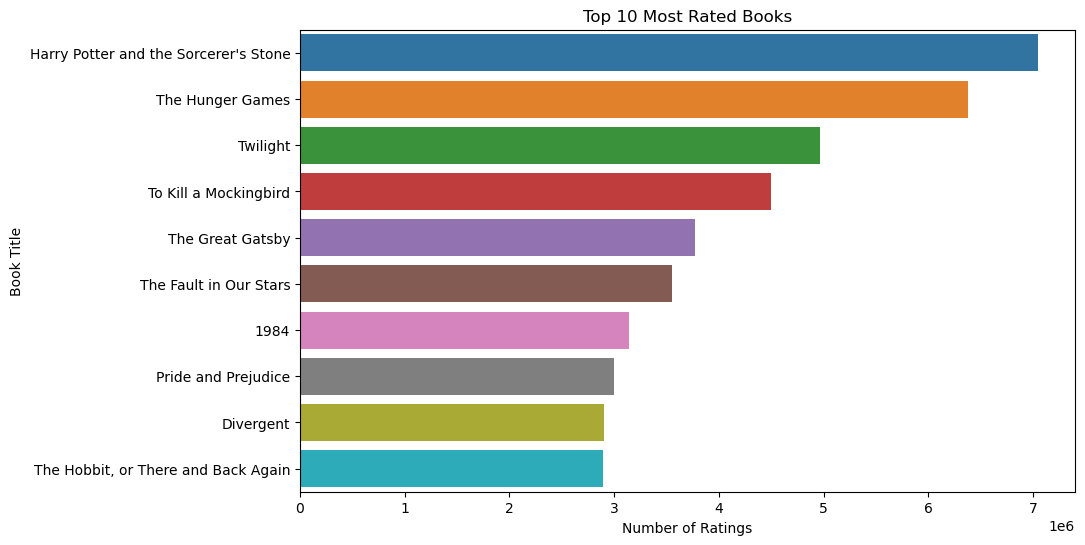

In [20]:
top_books = df.sort_values(
    by='numRatings',
    ascending=False
).head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_books,
    x='numRatings',
    y='title'
)

plt.title('Top 10 Most Rated Books')
plt.xlabel('Number of Ratings')
plt.ylabel('Book Title')

plt.show()

### 19. Authors with the Highest Total Number of Ratings

Group the data by author, add up `numRatings` for each author, sort the totals in descending order, and display the top ten.

In [21]:
author_ratings = (
    df.groupby('author')['numRatings']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(author_ratings)

author
J.K. Rowling, Mary GrandPré (Illustrator)    17790643
Suzanne Collins                              11654607
Stephenie Meyer                              10710870
Stephen King (Goodreads Author)              10263576
Rick Riordan (Goodreads Author)               8135714
Dan Brown (Goodreads Author)                  7041298
J.R.R. Tolkien                                6621548
J.K. Rowling                                  6560542
John Green (Goodreads Author)                 6355092
Cassandra Clare (Goodreads Author)            5637877
Name: numRatings, dtype: int64


### 20. Average Rating by Book Format

Group books by `bookFormat`, calculate the average rating for each format, and display the ten highest average ratings.

In [22]:
format_rating = (
    df.groupby('bookFormat')['rating']
    .mean()
    .sort_values(ascending=False)
)

print(format_rating.head(10))

bookFormat
Hard cover, Soft cover, e-book    5.000
kindle_edition                    5.000
Novel                             5.000
Paperback/Ebook                   5.000
Interactive ebook                 4.910
Fiction                           4.800
ebook and paperback               4.750
Slipcased Hardcover               4.682
Webnovel                          4.660
Pamphlet                          4.640
Name: rating, dtype: float64


### 21. Average Rating by Language

Group books by language, calculate the average rating for each language, and display the ten highest average ratings.

In [23]:
language_rating = (
    df.groupby('language')['rating']
    .mean()
    .sort_values(ascending=False)
)

print(language_rating.head(10))

language
French, Middle (ca.1400-1600)            5.000000
Maltese                                  5.000000
Iranian (Other)                          5.000000
Norwegian Nynorsk; Nynorsk, Norwegian    5.000000
Ukrainian                                4.606667
Mongolian                                4.440000
Macedonian                               4.400000
Korean                                   4.400000
Serbian                                  4.378611
Tagalog                                  4.372857
Name: rating, dtype: float64


### 22. Relationship Between Number of Ratings and Book Rating

Create a scatter plot with `numRatings` on the x-axis and `rating` on the y-axis. Each point represents a book. The graph helps us inspect whether these two variables appear related.

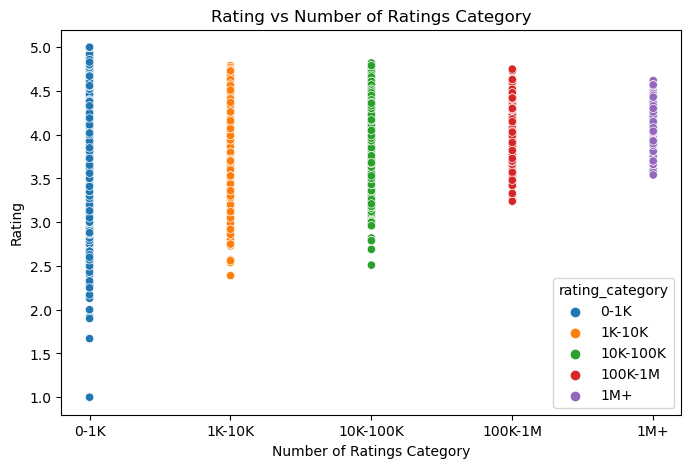

In [44]:
# numRatings categories
df['rating_category'] = pd.cut(
    df['numRatings'],
    bins=[0, 1000, 10000, 100000, 1000000, float('inf')],
    labels=['0-1K', '1K-10K', '10K-100K', '100K-1M', '1M+']
)

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='rating_category',
    y='rating',
    hue='rating_category'
)

plt.title('Rating vs Number of Ratings Category')
plt.xlabel('Number of Ratings Category')
plt.ylabel('Rating')

plt.show()

### 23. Correlation Between Number of Ratings and Book Rating

Calculate the correlation between `rating` and `numRatings`. The result ranges from -1 to +1: values near +1 indicate a positive relationship, values near -1 indicate a negative relationship, and values near 0 indicate little linear relationship.

In [25]:
print(
    df['rating'].corr(df['numRatings'])
)

0.014879799969936033


### 24. Distribution of Numerical Columns

Select all numerical columns and draw a histogram for each one. These graphs help us understand the distribution and spread of every numerical variable.

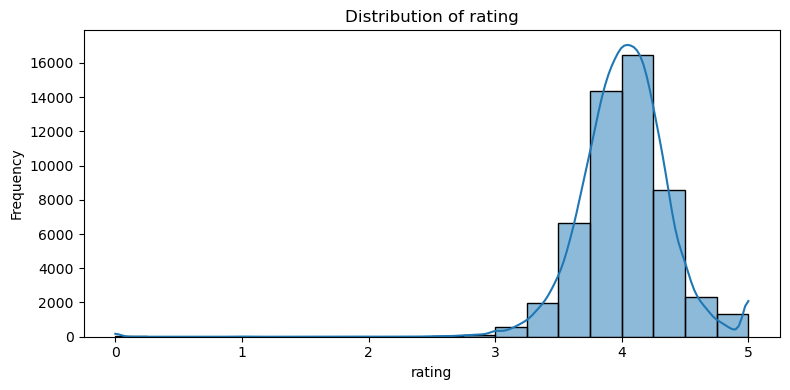

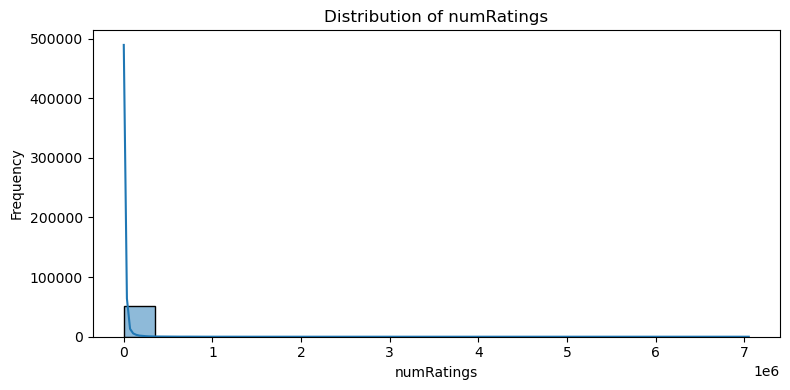

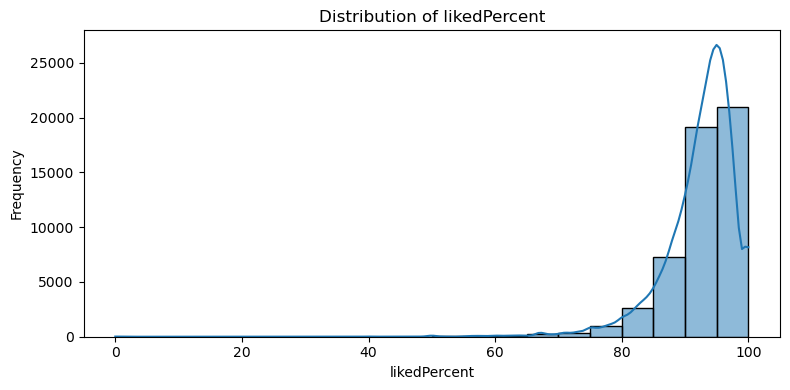

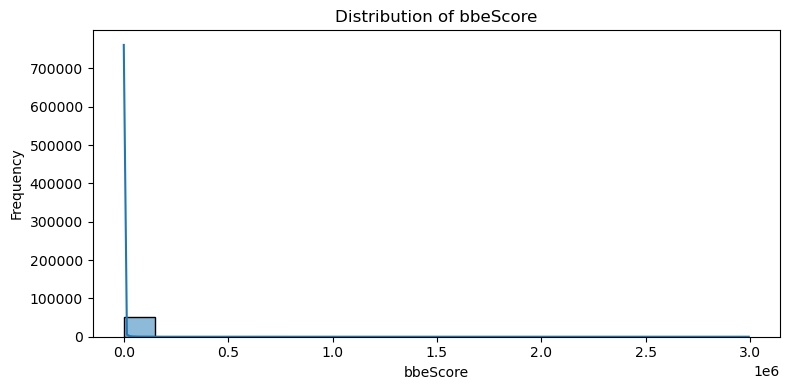

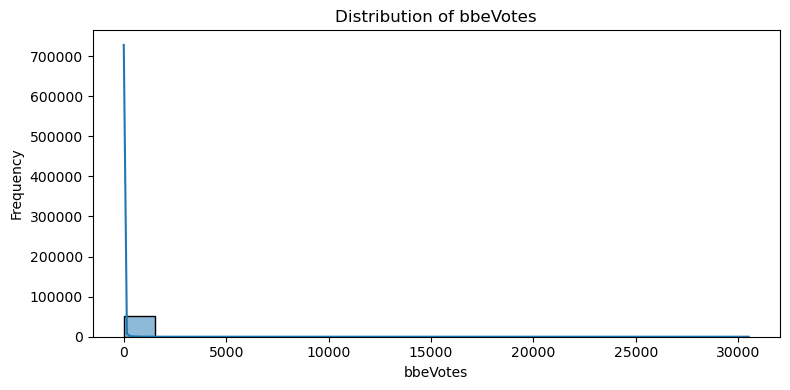

In [ ]:
numerical_cols = df.select_dtypes(
    include='number'
).columns

for col in numerical_cols:

    plt.figure(figsize=(8,4))

    sns.histplot(
        df[col],
        kde=True,
        bins=20
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

### 25. Top 10 Authors by Number of Books

Count the number of books for each author and create a horizontal bar chart showing the ten authors with the most books in the dataset.

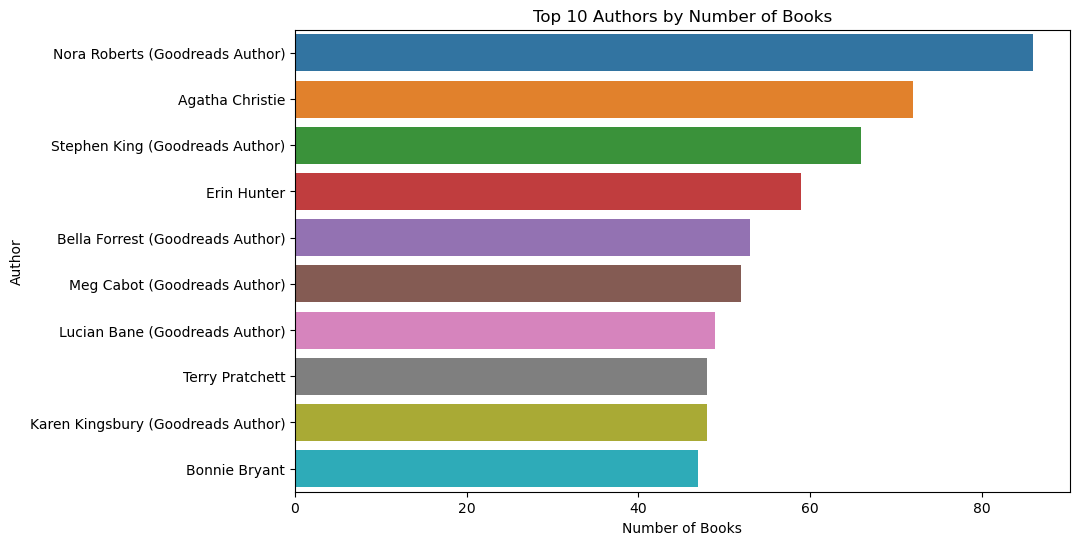

In [27]:
top_authors = df['author'].value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_authors.values,
    y=top_authors.index
)

plt.title('Top 10 Authors by Number of Books')
plt.xlabel('Number of Books')
plt.ylabel('Author')

plt.show()

### 26. Most Common Book Formats

Create a count plot for the ten most common book formats. Each bar shows the number of books available in that format.

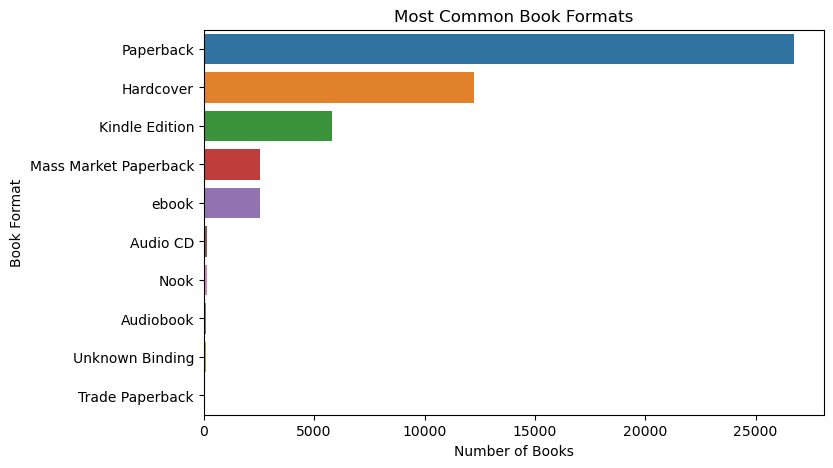

In [28]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    y='bookFormat',
    order=df['bookFormat'].value_counts().head(10).index
)

plt.title('Most Common Book Formats')
plt.xlabel('Number of Books')
plt.ylabel('Book Format')

plt.show()

## Outlier Detection

### 27. Detect Possible Outliers Using Boxplots

Create boxplots for all numerical columns. Points beyond the whiskers may indicate possible outliers. A boxplot also shows the median and the spread of the data.

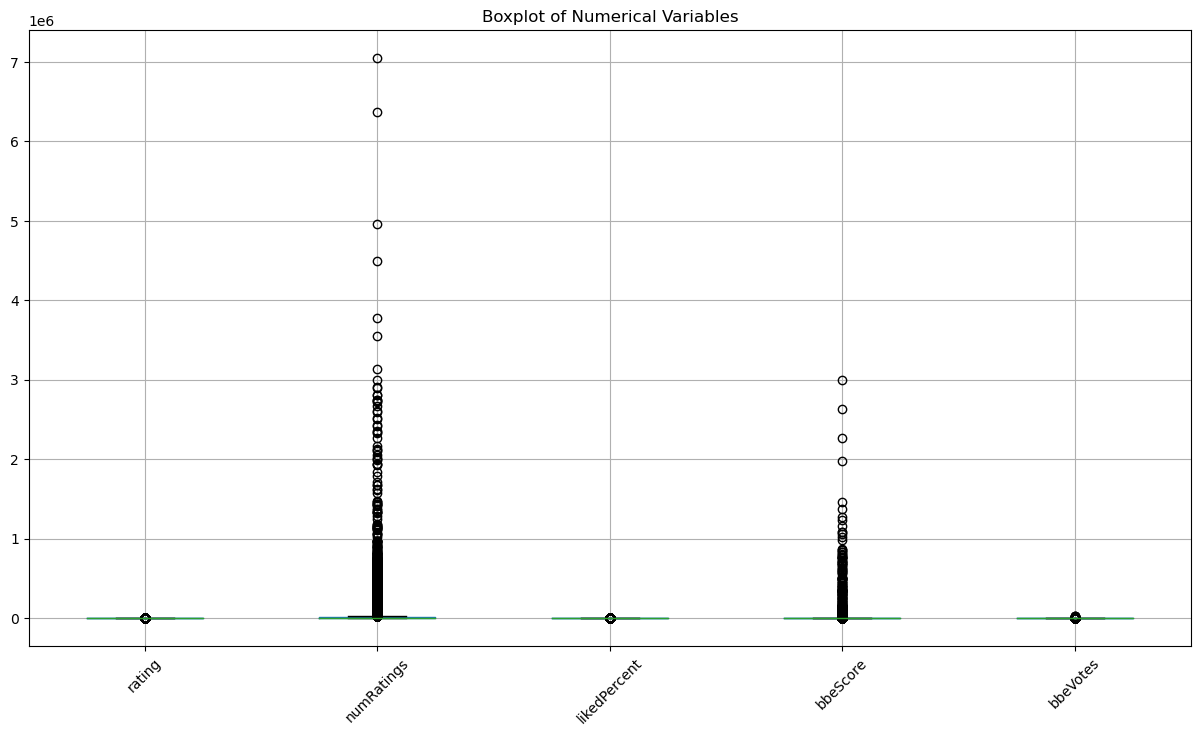

In [29]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

plt.figure(figsize=(15,8))

df[numeric_columns].boxplot()

plt.xticks(rotation=45)
plt.title('Boxplot of Numerical Variables')

plt.show()

### 28. Calculate the IQR Limits for Book Ratings

Calculate the first quartile (Q1), third quartile (Q3), and interquartile range (IQR). The lower and upper limits are calculated using Q1 - 1.5 × IQR and Q3 + 1.5 × IQR. These limits help identify possible rating outliers.

In [30]:
Q1 = df['rating'].quantile(0.25)
Q3 = df['rating'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Limit:", lower)
print("Upper Limit:", upper)

Lower Limit: 3.204999999999999
Upper Limit: 4.8450000000000015


### 29. Count Rating Outliers

Select rows where the rating is below the lower limit or above the upper limit, then print the number of such rows.

In [31]:
outliers = df[
    (df['rating'] < lower) |
    (df['rating'] > upper)
]

print("Number of rating outliers:", len(outliers))

Number of rating outliers: 1663


## Feature Engineering

### 30. Extract the Publication Year

Convert `publishDate` into a datetime format. Invalid or unrecognized dates become missing values because `errors='coerce'` is used. Then extract the year into a new column called `Publish_Year`.

In [32]:
df['publishDate'] = pd.to_datetime(
    df['publishDate'],
    errors='coerce'
)

df['Publish_Year'] = df['publishDate'].dt.year

### 31. Count Books Published Each Year

Count how many books were published in each year and sort the results by year.

In [33]:
books_by_year = df['Publish_Year'].value_counts().sort_index()

print(books_by_year)

1820.0    1
1873.0    1
1880.0    1
1884.0    1
1887.0    1
         ..
2069.0    1
2072.0    1
2073.0    1
2074.0    1
2075.0    1
Name: Publish_Year, Length: 129, dtype: int64


### 32. Visualize Books Published Each Year

Draw a line plot showing the number of books published in each year. The x-axis represents the publication year and the y-axis represents the number of books.

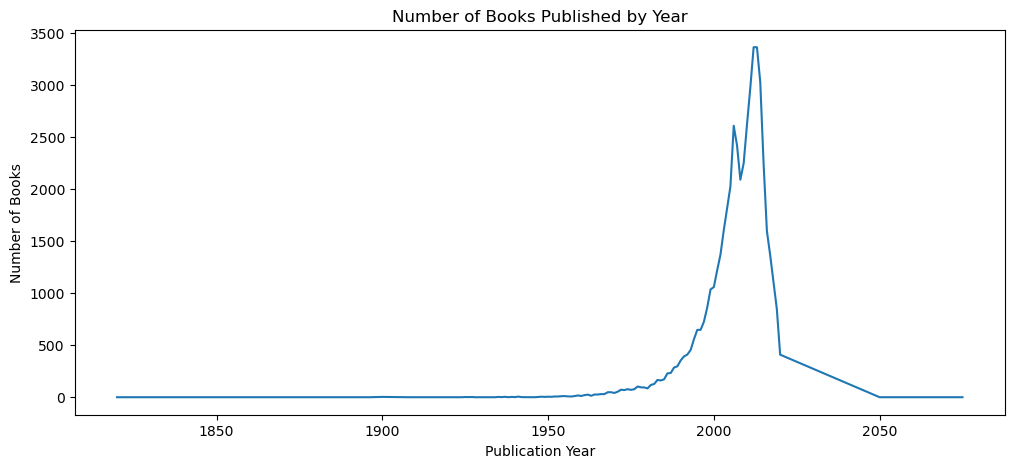

In [34]:
plt.figure(figsize=(12,5))

books_by_year.plot()

plt.title('Number of Books Published by Year')
plt.xlabel('Publication Year')
plt.ylabel('Number of Books')

plt.show()

### 33. Average Book Rating by Publication Year

Group books by publication year, calculate the average rating for each year, and plot the results as a line graph.

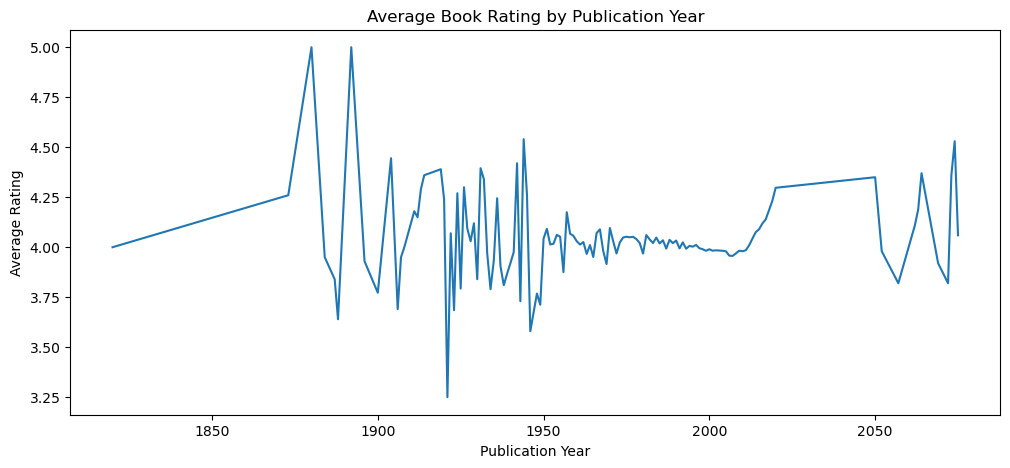

In [35]:
year_rating = (
    df.groupby('Publish_Year')['rating']
    .mean()
)

plt.figure(figsize=(12,5))

year_rating.plot()

plt.title('Average Book Rating by Publication Year')
plt.xlabel('Publication Year')
plt.ylabel('Average Rating')

plt.show()

### 34. Top 10 Books by BBE Score

Sort the books by `bbeScore` in descending order and display the ten books with the highest scores, including their title, author, rating, and BBE score.

In [36]:
top_bbe = df.sort_values(
    by='bbeScore',
    ascending=False
).head(10)

print(
    top_bbe[
        ['title', 'author', 'rating', 'bbeScore']
    ]
)

                                               title  \
0                                   The Hunger Games   
1          Harry Potter and the Order of the Phoenix   
2                              To Kill a Mockingbird   
3                                Pride and Prejudice   
4                                           Twilight   
5                                     The Book Thief   
6                                        Animal Farm   
7                           The Chronicles of Narnia   
8  J.R.R. Tolkien 4-Book Boxed Set: The Hobbit an...   
9                                 Gone with the Wind   

                                              author  rating  bbeScore  
0                                    Suzanne Collins    4.33   2993816  
1          J.K. Rowling, Mary GrandPré (Illustrator)    4.50   2632233  
2                                         Harper Lee    4.28   2269402  
3          Jane Austen, Anna Quindlen (Introduction)    4.26   1983116  
4                 

### 35. Visualize the Top 10 Books by BBE Score

Create a horizontal bar chart showing the ten books with the highest BBE scores. Longer bars indicate higher BBE scores.

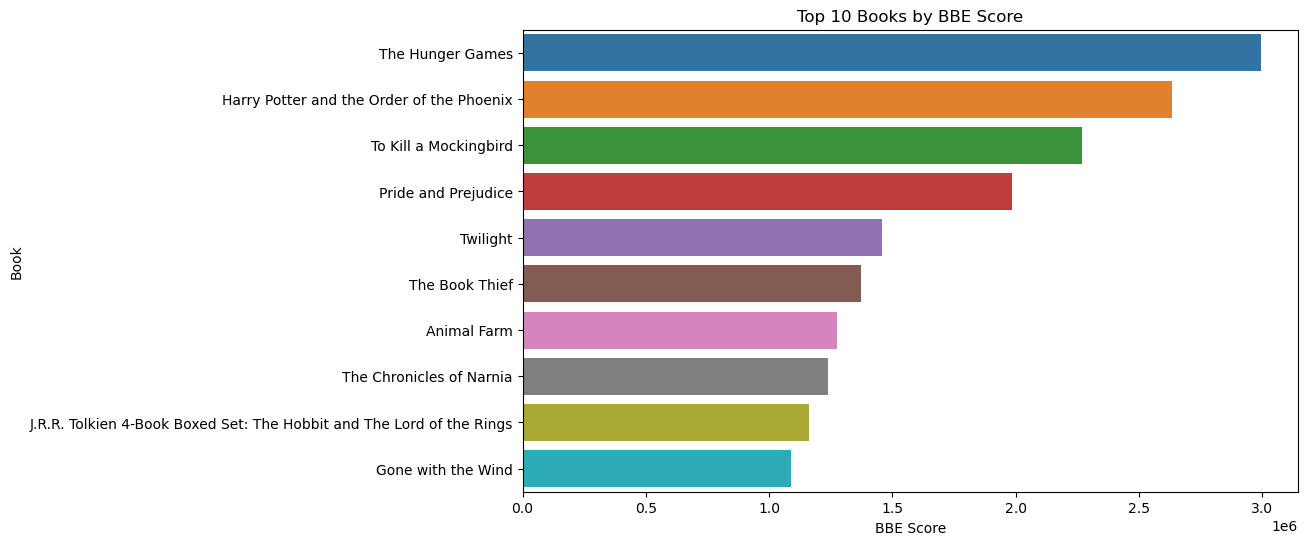

In [37]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_bbe,
    x='bbeScore',
    y='title'
)

plt.title('Top 10 Books by BBE Score')
plt.xlabel('BBE Score')
plt.ylabel('Book')

plt.show()

### 36. Relationship Between Rating and Liked Percentage

Create a scatter plot with book rating on the x-axis and liked percentage on the y-axis. Each point represents one book.

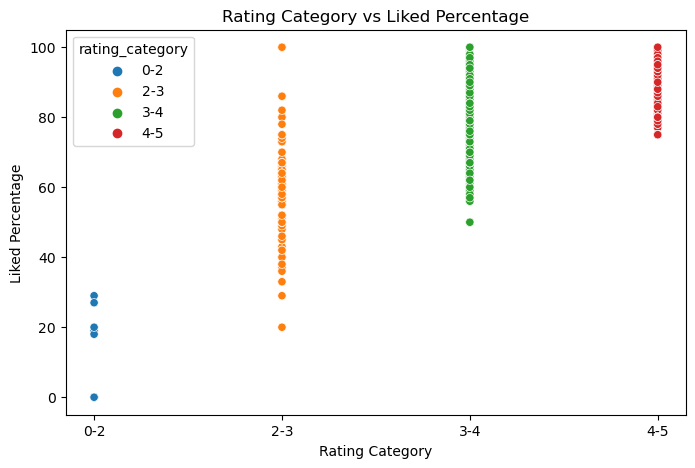

In [45]:
plt.figure(figsize=(8,5))

df['rating_category'] = pd.cut(
    df['rating'],
    bins=[0, 2, 3, 4, 5],
    labels=['0-2', '2-3', '3-4', '4-5'],
    include_lowest=True
)

sns.scatterplot(
    data=df,
    x='rating_category',
    y='likedPercent',
    hue='rating_category'
)

plt.title('Rating Category vs Liked Percentage')
plt.xlabel('Rating Category')
plt.ylabel('Liked Percentage')

plt.show()

### 37. Correlation Between Rating and Liked Percentage

Calculate the correlation between `rating` and `likedPercent` to measure the strength and direction of their linear relationship.

In [39]:
print(
    df['rating'].corr(df['likedPercent'])
)

0.8054361717075382


### 38. Top 10 Publishers

Count how many books are listed for each publisher and display the ten publishers with the highest counts.

In [40]:
top_publishers = df['publisher'].value_counts().head(10)

print(top_publishers)

Vintage                                        572
HarperCollins                                  562
Penguin Books                                  430
Ballantine Books                               399
Bantam                                         369
Createspace Independent Publishing Platform    367
Pocket Books                                   314
Avon                                           311
Berkley                                        287
Del Rey                                        284
Name: publisher, dtype: int64


### 39. Visualize the Top 10 Publishers

Create a horizontal bar chart showing the ten publishers with the most books in the dataset.

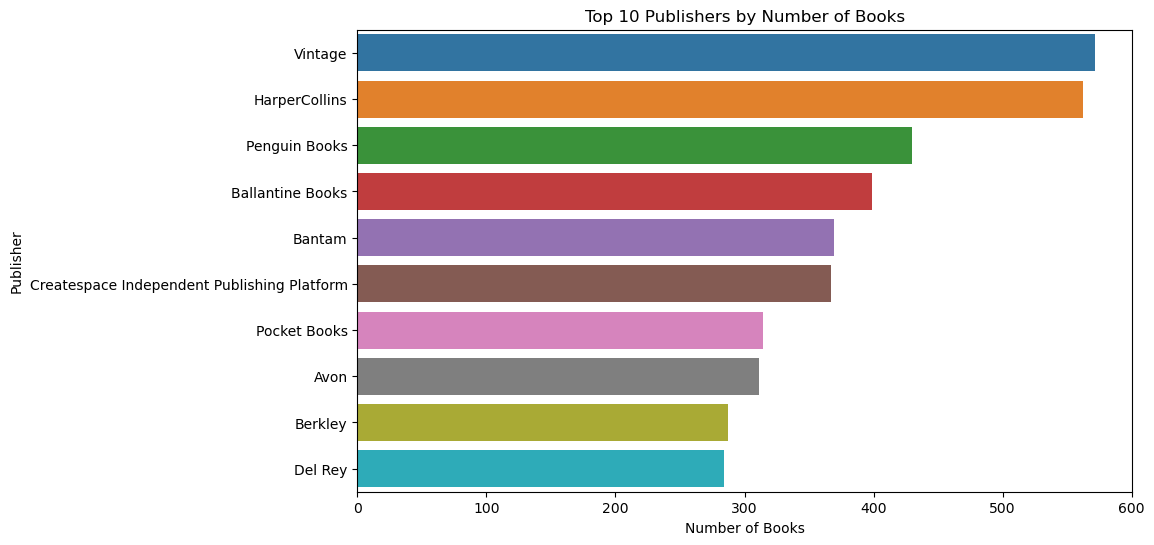

In [41]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=top_publishers.values,
    y=top_publishers.index
)

plt.title('Top 10 Publishers by Number of Books')
plt.xlabel('Number of Books')
plt.ylabel('Publisher')

plt.show()

### 40. Review Dataset Information After Analysis

Display the DataFrame information again to check the columns, non-null values, and data types after the analysis and feature engineering steps.

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 52428 entries, 0 to 52477
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   bookId            52428 non-null  object        
 1   title             52428 non-null  object        
 2   series            23445 non-null  object        
 3   author            52428 non-null  object        
 4   rating            52428 non-null  float64       
 5   description       51092 non-null  object        
 6   language          48627 non-null  object        
 7   isbn              52428 non-null  object        
 8   genres            52428 non-null  object        
 9   characters        52428 non-null  object        
 10  bookFormat        50955 non-null  object        
 11  edition           4949 non-null   object        
 12  pages             50085 non-null  object        
 13  publisher         48736 non-null  object        
 14  publishDate       5064

### 41. Check the Final Dataset Shape

Display the final number of rows and columns in the DataFrame.

In [43]:
print(df.shape)

(52428, 26)


## Conclusion

In this project, we performed Exploratory Data Analysis (EDA) on the Books dataset. We explored the dataset, cleaned the data, handled missing values, and used different visualizations such as bar charts, histograms, and scatter plots to understand the data.

Through this analysis, we identified patterns, trends, and relationships between different book features. Data visualization helped us understand the dataset more clearly and gain useful insights.

Overall, this project helped us understand the importance of data cleaning, data analysis, and visualization in discovering meaningful information from raw data.
